# 🏃📊 Tracking data (ATD)

The **Automatic Tracking Data**: computer-vision output giving the position and speed of every
tracked object on the pitch, once per video frame, **including the ball**.

This notebook covers loading it, how it lines up with the frames you label, what it does not
contain, and how to look at it.

---

## Loading

The ATD is Metrica's **FIFA/EPTS** export — a metadata XML plus a raw text file — so
[kloppy](https://kloppy.pysport.org/user-guide/loading-data/metrica/) reads the pair directly.

The match was recorded twice. This is the **tactical** recording, the one a submission is
indexed to; `source='broadcast'` gets the other, on its own timeline.

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath('..'))

%pip install matplotlib

import numpy as np
import matplotlib.pyplot as plt
from kloppy import metrica

import games

paths = games.asset_paths(source='tactical')

# The full file is 199,319 frames. Enough here to reach the first-half kickoff at 11185.
dataset = metrica.load_tracking_epts(meta_data=paths['atd_meta'],
                                     raw_data=paths['atd_raw'],)
                                     #limit=36000)
print('%d frames loaded' % len(dataset.records))

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.
199319 frames loaded


## The data as a table

Each row is one video frame:

- **frame_id** — the tracking's own counter, starting at **1**
- **ball_x**, **ball_y** — the ball, when it is visible
- **1_x**, **1_y**, **1_s** — position and speed (m/s) of track slot 1, and so on

All positions are **normalised to 0–1**, not metres. At 25 fps, 25 rows is one second.

In [2]:
import pandas as pd

frame_df = dataset.to_df()
frame_df.head()

,period_id,timestamp,frame_id,ball_state,ball_owning_team_id,ball_x,ball_y,ball_z,ball_speed,1_x,...,44_d,44_s,45_x,45_y,45_d,45_s,46_x,46_y,46_d,46_s
0,1,0 days 00:00:00.040000,1,None,None,NaN,NaN,None,None,0.33411,...,None,NaN,NaN,NaN,None,NaN,0.06057,0.39965,None,NaN
1,1,0 days 00:00:00.080000,2,None,None,NaN,NaN,None,None,0.33404,...,None,NaN,NaN,NaN,None,NaN,0.06057,0.39965,None,NaN
2,1,0 days 00:00:00.120000,3,None,None,NaN,NaN,None,None,0.33396,...,None,NaN,NaN,NaN,None,NaN,0.06057,0.39965,None,NaN
3,1,0 days 00:00:00.160000,4,None,None,NaN,NaN,None,None,0.33389,...,None,NaN,NaN,NaN,None,NaN,0.06057,0.39965,None,NaN
4,1,0 days 00:00:00.200000,5,None,None,NaN,NaN,None,None,0.33382,...,None,NaN,NaN,NaN,None,NaN,0.06057,0.39965,None,NaN


In [3]:
frame_df = dataset.to_df()


first_15_min = frame_df.loc[
    frame_df["timestamp"] >= pd.Timedelta(minutes=15) ]

first_18_min = frame_df.loc[
    frame_df["timestamp"] >= pd.Timedelta(minutes=18) ]

first_21_min = frame_df.loc[
    frame_df["timestamp"] >= pd.Timedelta(minutes=21) ]

'''
frame_df = dataset.to_df()
first_15_min = frame_df.loc[frame_df["timestamp"] >= pd.Timedelta(minutes=15)].head()
'''

first_15_min.head()
first_18_min.head()
#first_21_min.head()

,period_id,timestamp,frame_id,ball_state,ball_owning_team_id,ball_x,ball_y,ball_z,ball_speed,1_x,...,44_d,44_s,45_x,45_y,45_d,45_s,46_x,46_y,46_d,46_s
26999,1,0 days 00:18:00,27000,None,None,0.91302,0.51485,None,None,NaN,...,None,NaN,0.82440,0.70483,None,1.258564,0.91629,0.51454,None,0.985430
27000,1,0 days 00:18:00.040000,27001,None,None,0.91350,0.51454,None,None,NaN,...,None,NaN,0.82493,0.70502,None,1.288337,0.91664,0.51433,None,0.987745
27001,1,0 days 00:18:00.080000,27002,None,None,0.91398,0.51421,None,None,NaN,...,None,NaN,0.82546,0.70521,None,1.314786,0.91699,0.51412,None,0.989567
27002,1,0 days 00:18:00.120000,27003,None,None,0.91445,0.51387,None,None,NaN,...,None,NaN,0.82599,0.70539,None,1.337592,0.91734,0.51391,None,0.990570
27003,1,0 days 00:18:00.160000,27004,None,None,0.91490,0.51351,None,None,NaN,...,None,NaN,0.82651,0.70555,None,1.356559,0.91768,0.51370,None,0.990458


In [4]:
frame_df.columns

Index(['period_id', 'timestamp', 'frame_id', 'ball_state',
       'ball_owning_team_id', 'ball_x', 'ball_y', 'ball_z', 'ball_speed',
       '1_x',
       ...
       '44_d', '44_s', '45_x', '45_y', '45_d', '45_s', '46_x', '46_y', '46_d',
       '46_s'],
      dtype='object', length=193)

## Frame alignment — a single subtraction

The ATD counts from 1 and your submission counts from 0:

```
video_frame = frame_id - 1
```

That is the whole alignment story. `load_atd.check_alignment()` verifies it rather than
asserting it — the record count must equal the video length, and the ids must be exactly
`1..n` with nothing missing.

In [5]:
import load_atd

# Straight off the raw file -- one streaming pass, no kloppy. Loading all 199,319 frames through
# kloppy just to count them would cost minutes and gigabytes.
report = load_atd.check_alignment_raw()
for key, value in report.items():
    print('%-18s %s' % (key, value))

n_records          199319
n_video_frames     199319
frame_id_range     (1, 199319)
contiguous         True
first_video_frame  0
agrees             True


## What it does not contain

### No player identities

There are **46 track slots** for 22 players. They are named `Track 1`…`Track 46` and their
`ShirtNumber` is just the slot index — **not a shirt number, and not a person**. Slots start,
stop and swap identity as the tracker loses and re-acquires people.

You get positions and team membership. Any analysis you build has to be collective.

In [6]:
players = dataset.metadata.teams[0].players + dataset.metadata.teams[1].players
print('%d track slots' % len(players))
for player in players[:3]:
    print('  %-10s shirt %-3s team %s' % (player.name, player.jersey_no, player.team))
print('  ...')

#print(players) 

46 track slots
  Track 1    shirt 1   team Barcelona
  Track 2    shirt 2   team Barcelona
  Track 3    shirt 3   team Barcelona
  ...


### The ball is missing 43% of the time

The ball is the most informative signal in the file and the least reliable one. Count it
yourself before building anything that assumes it is there.

In [7]:
ball = frame_df[['ball_x', 'ball_y']]
seen = ball.notna().all(axis=1)
print('ball present on %d of %d loaded frames (%.1f%%)' % (seen.sum(), len(seen),
                                                           100 * seen.mean()))
print()
print('over the whole match it is 56.9%. See DATA.md.')

ball present on 113488 of 199319 loaded frames (56.9%)

over the whole match it is 56.9%. See DATA.md.


## Pitch dimensions

Positions are normalised, so multiply by the real pitch to get metres.

In [8]:
length = dataset.metadata.pitch_dimensions.pitch_length
width = dataset.metadata.pitch_dimensions.pitch_width
print('ATD metadata: %s x %s m' % (length, width))
print('games.py:     %s x %s m  (measured from the corrected tracking)'
      % games.GAMES[games.GAME]['pitch'])

ATD metadata: 105 x 68 m
games.py:     105.3 x 68.0 m  (measured from the corrected tracking)


## Looking at a frame

`starter/utils.py` draws a pitch and plots both teams **and the ball**. The kickoff of the
first half is video frame 11185, which is also the first frame the ground truth grades.

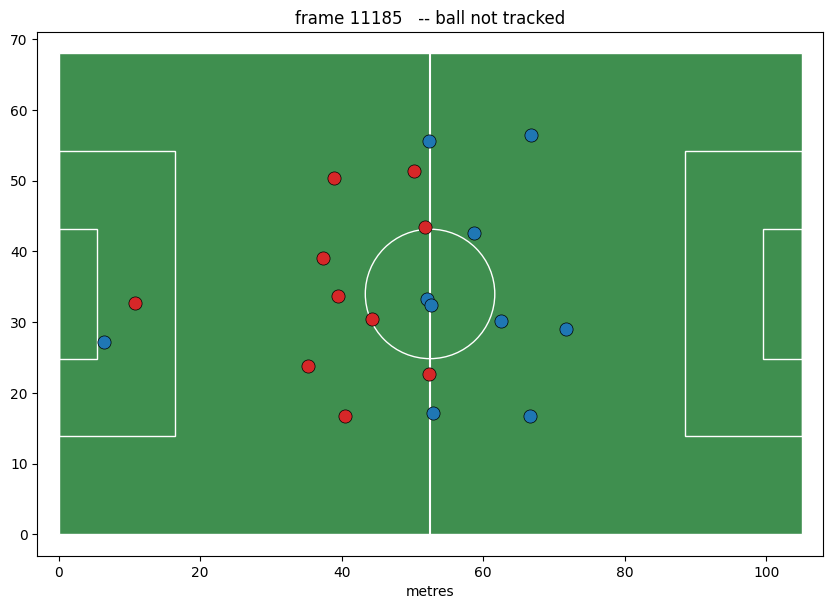

In [9]:
from utils import plot_frame

plot_frame(dataset, 11185)   # 1st half kickoff
plt.show()

Now a frame where the tracking has lost the ball. The title says so — there is no white dot,
and that is the data being honest rather than a plotting bug.

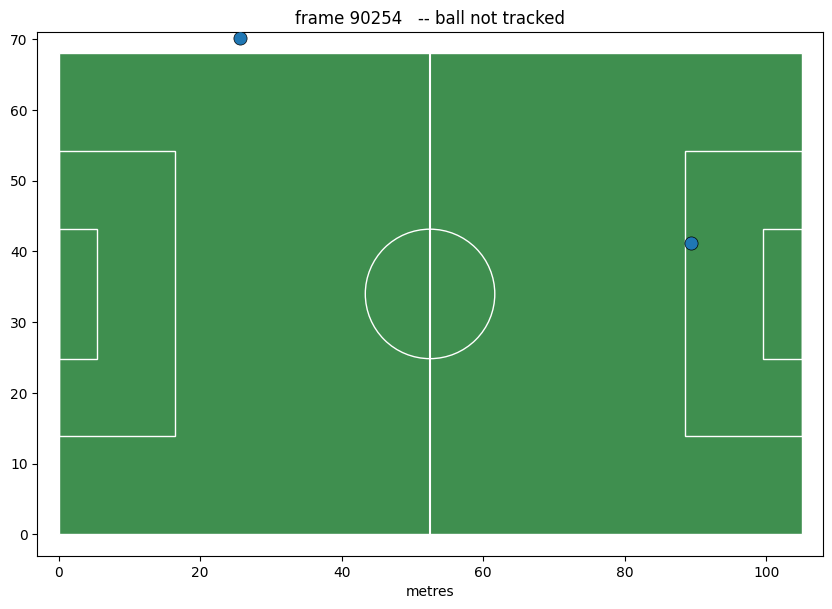

In [10]:
missing = int(np.flatnonzero(~seen.values)[len(np.flatnonzero(~seen.values)) // 2])
plot_frame(dataset, missing)
plt.show()

## Watching it move

A static frame hides the thing that actually tells you who has the ball: how the shape moves.

The ball simply disappears on frames where it was not tracked.

In [11]:
from IPython.display import HTML
from utils import animate_frames

anim = animate_frames(dataset, 11185, 11435)   # 10 seconds from kickoff
HTML(anim.to_jshtml())

---

**Next:** [`03_first_submission.ipynb`](03_first_submission.ipynb) turns this into a scored
submission in one sitting.

## ball not visible for more than 5 min 

Missing-position stretches longer than 5 seconds: 142


,period_id,start,end,duration,frames
0,1,0 days 00:00:00.040000,0 days 00:02:47.680000,0 days 00:02:47.680000,4192
2,1,0 days 00:02:48.320000,0 days 00:03:22.040000,0 days 00:00:33.760000,844
4,1,0 days 00:03:24.360000,0 days 00:07:05.720000,0 days 00:03:41.400000,5535
6,1,0 days 00:07:08.640000,0 days 00:07:20.120000,0 days 00:00:11.520000,288
8,1,0 days 00:07:21.440000,0 days 00:07:27.480000,0 days 00:00:06.080000,152
...,...,...,...,...,...
362,1,0 days 02:04:57.680000,0 days 02:05:06.800000,0 days 00:00:09.160000,229
364,1,0 days 02:05:37.320000,0 days 02:05:44.360000,0 days 00:00:07.080000,177
366,1,0 days 02:06:13.760000,0 days 02:06:36.800000,0 days 00:00:23.080000,577
368,1,0 days 02:06:43.080000,0 days 02:06:59.720000,0 days 00:00:16.680000,417


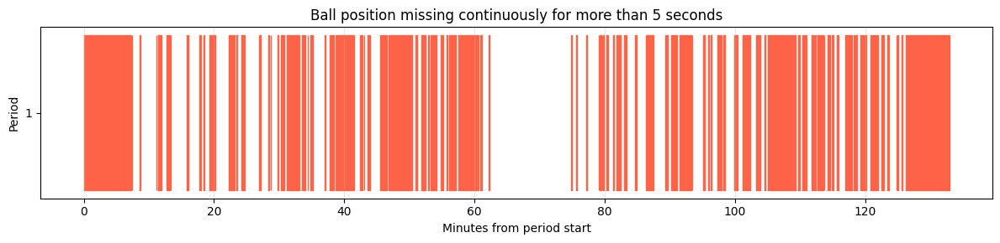

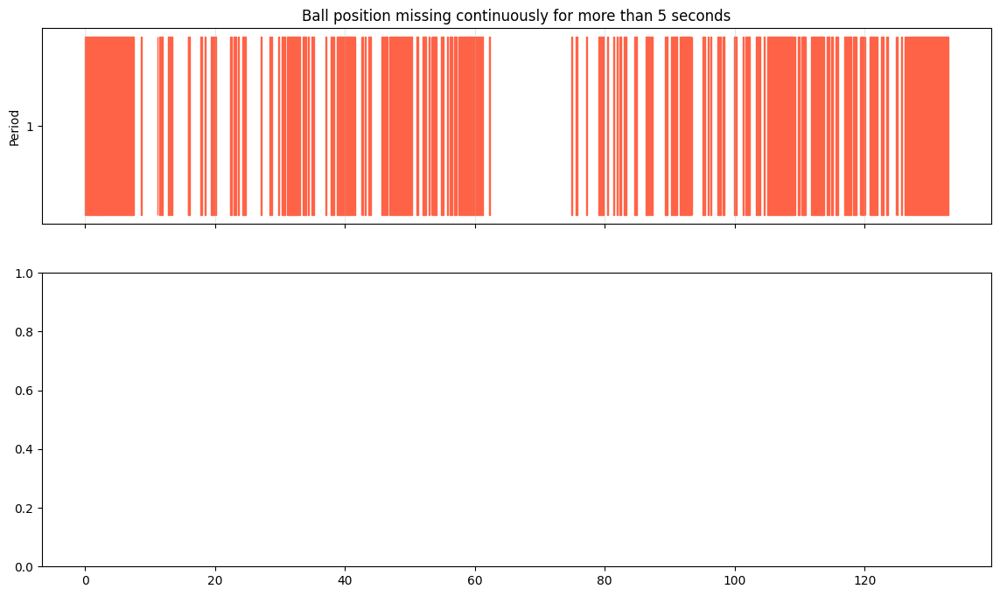

In [14]:
import pandas as pd
import matplotlib.pyplot as plt

df = frame_df.sort_values(["period_id", "timestamp"]).copy()

# Treat the ball position as missing if either coordinate is null.
df["ball_missing"] = df[["ball_x", "ball_y"]].isna().any(axis=1)

# Assign an ID to each consecutive stretch of missing or present positions,
# separately within each period.
df["run_id"] = df.groupby("period_id")["ball_missing"].transform(
    lambda values: values.ne(values.shift()).cumsum()
)

runs = (
    df.groupby(["period_id", "run_id"])
    .agg(
        is_missing=("ball_missing", "first"),
        start=("timestamp", "min"),
        end=("timestamp", "max"),
        frames=("timestamp", "size"),
    )
    .reset_index()
)

# Include the duration of the final frame in each stretch.
frame_step = df.groupby("period_id")["timestamp"].diff().dropna().median()
runs["duration"] = runs["end"] - runs["start"] + frame_step

long_gaps = runs.loc[
    runs["is_missing"] & (runs["duration"] > pd.Timedelta(seconds=5))
].copy()

print(f"Missing-position stretches longer than 5 seconds: {len(long_gaps)}")
display(long_gaps[["period_id", "start", "end", "duration", "frames"]])

# Plot each long missing stretch on its period's timeline.
periods = sorted(df["period_id"].dropna().unique())
fig, ax = plt.subplots(figsize=(12, max(3, 0.7 * len(periods))))

for y, period in enumerate(periods):
    gaps = long_gaps.loc[long_gaps["period_id"] == period]
    spans = [
        (start.total_seconds() / 60, duration.total_seconds() / 60)
        for start, duration in zip(gaps["start"], gaps["duration"])
    ]
    if spans:
        ax.broken_barh(spans, (y - 0.35, 0.7), color="tomato")

ax.set_yticks(range(len(periods)))
ax.set_yticklabels([str(period) for period in periods])
ax.set_xlabel("Minutes from period start")
ax.set_ylabel("Period")
ax.set_title("Ball position missing continuously for more than 5 seconds")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

import pandas as pd
import matplotlib.pyplot as plt
from load_smart_tagging import load as load_smart_tagging

# Find continuous stretches where the ball position is missing
tracking_df = frame_df.sort_values(["period_id", "timestamp"]).copy()
tracking_df["ball_missing"] = tracking_df[["ball_x", "ball_y"]].isna().any(axis=1)
tracking_df["run_id"] = tracking_df.groupby("period_id")["ball_missing"].transform(
    lambda values: values.ne(values.shift()).cumsum()
)

runs = (
    tracking_df.groupby(["period_id", "run_id"])
    .agg(
        is_missing=("ball_missing", "first"),
        start=("timestamp", "min"),
        end=("timestamp", "max"),
    )
    .reset_index()
)

frame_step = tracking_df.groupby("period_id")["timestamp"].diff().dropna().median()
runs["duration"] = runs["end"] - runs["start"] + frame_step

long_gaps = runs.loc[
    runs["is_missing"] & (runs["duration"] > pd.Timedelta(seconds=5))
].copy()

# Load Smart Tagging and keep the requested restart types
wanted_types = [
    "Throw-in",
    "Corner Kick",
    "Goal Kick",
    "Free Kick",
    "Kick Off (After Goal)",
    "Kick Off (Start)",
]

smart_tags = load_smart_tagging()
events_df = pd.DataFrame([
    {
        "half": event["tags"].get("Half", "Unknown"),
        "type": event["tags"].get("Type"),
        "start_s": event["start_s"],
        "end_s": event["end_s"],
    }
    for event in smart_tags
    if event["tags"].get("Type") in wanted_types
]).sort_values("start_s")

# Plot both timelines on the same match-video time axis
periods = sorted(tracking_df["period_id"].dropna().unique())
fig, (ax_gaps, ax_events) = plt.subplots(
    2, 1,
    sharex=True,
    figsize=(14, 8),
    gridspec_kw={"height_ratios": [1, 1.5]},
)

# Top panel: missing ball-position stretches
for y, period in enumerate(periods):
    gaps = long_gaps.loc[long_gaps["period_id"] == period]
    spans = [
        (start.total_seconds() / 60, duration.total_seconds() / 60)
        for start, duration in zip(gaps["start"], gaps["duration"])
    ]
    if spans:
        ax_gaps.broken_barh(spans, (y - 0.35, 0.7), color="tomato")

ax_gaps.set_yticks(range(len(periods)))
ax_gaps.set_yticklabels([str(period) for period in periods])
ax_gaps.set_ylabel("Period")
ax_gaps.set_title("Ball position missing continuously for more than 5 seconds")
ax_gaps.grid(axis="x", alpha=0.3)


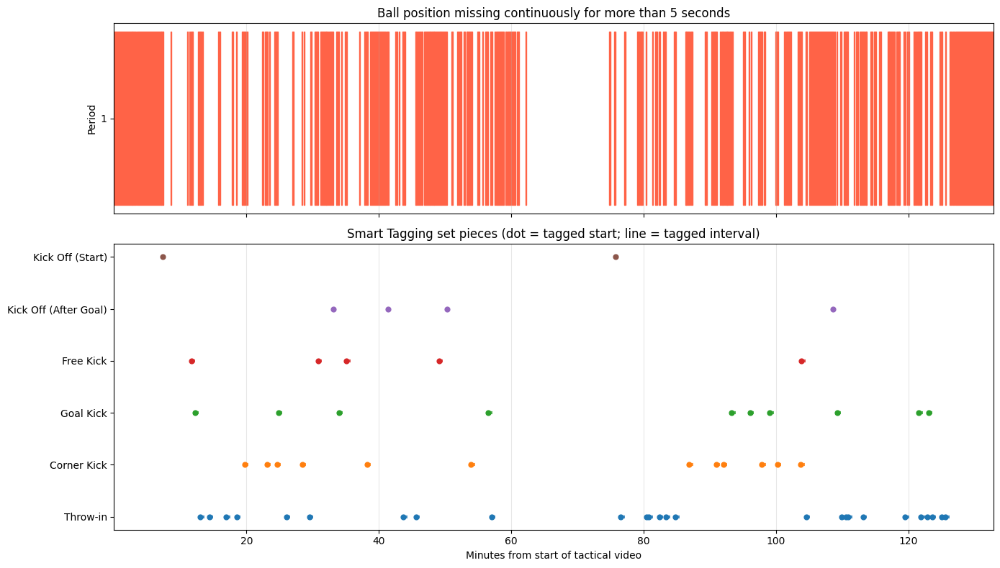

,half,type,start,end
0,1st Half,Kick Off (Start),07:23,07:28
56,1st Half,Free Kick,11:41,12:16
46,1st Half,Goal Kick,12:12,12:47
34,1st Half,Throw-in,13:01,13:36
40,1st Half,Throw-in,14:23,14:58
19,1st Half,Throw-in,16:56,17:31
29,1st Half,Throw-in,18:31,19:06
13,1st Half,Corner Kick,19:44,20:19
14,1st Half,Corner Kick,23:06,23:41
8,1st Half,Corner Kick,24:37,25:12


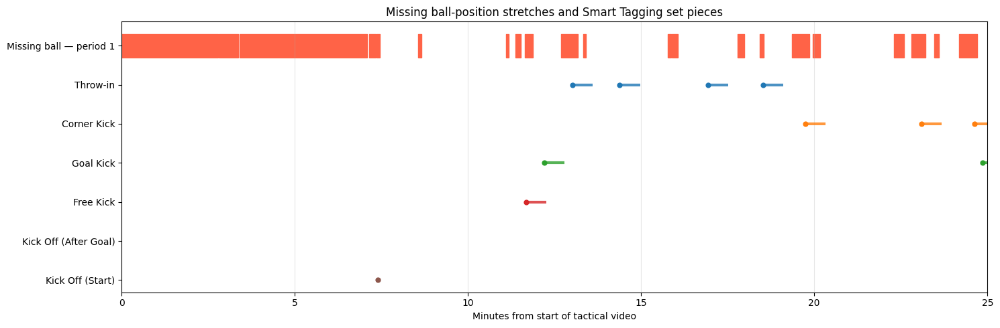

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
from load_smart_tagging import load as load_smart_tagging

# Find continuous stretches where the ball position is missing
tracking_df = frame_df.sort_values(["period_id", "timestamp"]).copy()
tracking_df["ball_missing"] = tracking_df[["ball_x", "ball_y"]].isna().any(axis=1)
tracking_df["run_id"] = tracking_df.groupby("period_id")["ball_missing"].transform(
    lambda values: values.ne(values.shift()).cumsum()
)

runs = (
    tracking_df.groupby(["period_id", "run_id"])
    .agg(
        is_missing=("ball_missing", "first"),
        start=("timestamp", "min"),
        end=("timestamp", "max"),
    )
    .reset_index()
)

frame_step = tracking_df.groupby("period_id")["timestamp"].diff().dropna().median()
runs["duration"] = runs["end"] - runs["start"] + frame_step

long_gaps = runs.loc[
    runs["is_missing"] & (runs["duration"] > pd.Timedelta(seconds=5))
].copy()

# Load Smart Tagging and keep the requested restart types
wanted_types = [
    "Throw-in",
    "Corner Kick",
    "Goal Kick",
    "Free Kick",
    "Kick Off (After Goal)",
    "Kick Off (Start)",
]

smart_tags = load_smart_tagging()
events_df = pd.DataFrame([
    {
        "half": event["tags"].get("Half", "Unknown"),
        "type": event["tags"].get("Type"),
        "start_s": event["start_s"],
        "end_s": event["end_s"],
    }
    for event in smart_tags
    if event["tags"].get("Type") in wanted_types
]).sort_values("start_s")

# Plot both timelines on the same match-video time axis
periods = sorted(tracking_df["period_id"].dropna().unique())
fig, (ax_gaps, ax_events) = plt.subplots(
    2, 1,
    sharex=True,
    figsize=(14, 8),
    gridspec_kw={"height_ratios": [1, 1.5]},
)

# Top panel: missing ball-position stretches
for y, period in enumerate(periods):
    gaps = long_gaps.loc[long_gaps["period_id"] == period]
    spans = [
        (start.total_seconds() / 60, duration.total_seconds() / 60)
        for start, duration in zip(gaps["start"], gaps["duration"])
    ]
    if spans:
        ax_gaps.broken_barh(spans, (y - 0.35, 0.7), color="tomato")

ax_gaps.set_yticks(range(len(periods)))
ax_gaps.set_yticklabels([str(period) for period in periods])
ax_gaps.set_ylabel("Period")
ax_gaps.set_title("Ball position missing continuously for more than 5 seconds")
ax_gaps.grid(axis="x", alpha=0.3)

# Bottom panel: Smart Tagging restart intervals
colors = plt.get_cmap("tab10")
for y, event_type in enumerate(wanted_types):
    events = events_df.loc[events_df["type"] == event_type]
    if not events.empty:
        ax_events.hlines(
            [y] * len(events),  # one y-position for each interval
            events["start_s"] / 60,
            events["end_s"] / 60,
            colors=colors(y),
            linewidth=3,
            alpha=0.8,
        )
        ax_events.scatter(
            events["start_s"] / 60,
            [y] * len(events),
            color=[colors(y)],
            s=24,
            zorder=3,
        )

ax_events.set_yticks(range(len(wanted_types)))
ax_events.set_yticklabels(wanted_types)
ax_events.set_xlabel("Minutes from start of tactical video")
ax_events.set_title("Smart Tagging set pieces (dot = tagged start; line = tagged interval)")
ax_events.grid(axis="x", alpha=0.3)

# Keep the timeline aligned to the full tracking video
ax_events.set_xlim(
    tracking_df["timestamp"].min().total_seconds() / 60,
    tracking_df["timestamp"].max().total_seconds() / 60,
)

plt.tight_layout()
plt.show()

# List event times as mm:ss from the start of the tactical video
def seconds_to_mmss(seconds):
    minutes, secs = divmod(int(seconds), 60)
    return f"{minutes:02d}:{secs:02d}"

event_table = events_df.assign(
    start=events_df["start_s"].map(seconds_to_mmss),
    end=events_df["end_s"].map(seconds_to_mmss),
)
display(event_table[["half", "type", "start", "end"]])

# Plot missing-ball stretches and Smart Tagging events on one axes
periods = sorted(tracking_df["period_id"].dropna().unique())
fig, ax = plt.subplots(figsize=(15, max(5, 0.7 * (len(periods) + len(wanted_types)))))

# Create a separate row for each period's missing-ball stretches,
# followed by a row for each Smart Tagging event type.
gap_rows = {
    period: i for i, period in enumerate(periods)
}
event_row_offset = len(periods)

# Missing-ball stretches
for period, y in gap_rows.items():
    gaps = long_gaps.loc[long_gaps["period_id"] == period]
    for _, gap in gaps.iterrows():
        ax.broken_barh(
            [(gap["start"].total_seconds() / 60,
              gap["duration"].total_seconds() / 60)],
            (y - 0.3, 0.6),
            color="tomato",
        )

# Smart Tagging intervals
colors = plt.get_cmap("tab10")
for i, event_type in enumerate(wanted_types):
    y = event_row_offset + i
    events = events_df.loc[events_df["type"] == event_type]

    if not events.empty:
        ax.hlines(
            [y] * len(events),
            events["start_s"] / 60,
            events["end_s"] / 60,
            colors=colors(i),
            linewidth=3,
            alpha=0.8,
        )
        ax.scatter(
            events["start_s"] / 60,
            [y] * len(events),
            color=[colors(i)],
            s=24,
            zorder=3,
        )

# Label every row
row_labels = (
    [f"Missing ball — period {period}" for period in periods]
    + wanted_types
)
ax.set_yticks(range(len(row_labels)))
ax.set_yticklabels(row_labels)
ax.invert_yaxis()


max_minutes = max(
    tracking_df["timestamp"].max().total_seconds(),
    events_df["end_s"].max(),
) / 60

ax.set_xlim(0, 25)
ax.set_xlabel("Minutes from start of tactical video")
ax.set_title("Missing ball-position stretches and Smart Tagging set pieces")
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()